<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex03_CNN_%EC%9D%B4%ED%95%B4%ED%95%98%EA%B8%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 작업 디렉토리 변경
%cd "/content/drive/MyDrive/Colab Notebooks/딥러닝 기초"

/content/drive/MyDrive/Colab Notebooks/딥러닝 기초


### 학습목표
- CNN 알고리즘의 필요성을 이해하고 동작원리를 파악한다
- keras를 활용해 CNN모델을 구성한다

### 5가지 동물 분류  MLP만들기
- 데이터로딩 > 학습 > 평가



In [ ]:
# 데이터로딩
import numpy as np
from tqdm import tqdm # 반복문 작업의 진척률을 시각화하는 도구
from tensorflow.keras.utils import image_dataset_from_directory # 폴더에서 이미지를 불러오는 도구
import matplotlib.pyplot as plt # 시각화 도구
# 전처리 (특징추출)
from tensorflow.keras.layers import Conv2D # 입력데이터의 특징을 강조하는 레이어(학습하는 대상)
from tensorflow.keras.layers import MaxPool2D # 불필요한 정보를 제거하는 레이어
# 학습
from tensorflow.keras.models import Sequential # 인공신경망을 구성하는 기본 틀
from tensorflow.keras.layers import Dense # 뇌세포를 담당하는 도구
from tensorflow.keras.layers import InputLayer # 인공신경망의 입력모양을 지정하는 도구
from tensorflow.keras.layers import Flatten # 데이터를 1차원으로 평탄화하는 도구
from tensorflow.keras.optimizers import Adam # 경사하강법 종류
# 전이학습
from tensorflow.keras.applications import VGG16 # 2014 imagenet 준우승 모델
from tensorflow.keras.applications.vgg16 import preprocess_input # vgg16용 전처리 함수
#평가
from sklearn.metrics import classification_report # 분류모델의 성능을 평가하는 도구

### 데이터 로드

#### 훈련용데이터 로드

In [ ]:
# 폴더에서 이미지데이터 정보 불러오기
train_data = image_dataset_from_directory(
    directory = "./data/train", # 읽어들일 경로
    labels='inferred', # 폴더명을 인식해서 정답으로 지정
    label_mode='int', # 정답을 지정된 숫자 형식으로 변환
    color_mode='rgb', # 이미지를 컬러 채널로 로딩
    batch_size=32, # 한번에 처리하는 데이터 수 (메모리 관련)
    image_size=(224, 224) # 이미지 리사이징 크기 (서로 다른 크기의 이미지를 통일)
)

Found 2500 files belonging to 5 classes.


In [ ]:
# 훈련용 데이터가 저장될 리스트 생성
X_train = []
y_train = []

In [ ]:
# 반복문을 이용해서 데이터 (사진, 정답라벨) 읽기
for img, label in tqdm(train_data.as_numpy_iterator()) :
  X_train.append(img) # 32개씩 이미지 묶음을 리스트에 저장
  y_train.append(label) # 32개씩 정답 묶음을 리스트에 저장

79it [06:16,  4.77s/it]


In [ ]:
# 32개씩 묶은 넘파이 배열을 하나로 통합
X_train_final = np.concat(X_train)
y_train_final = np.concat(y_train)

In [ ]:
X_train_final.shape, y_train_final.shape

((2500, 224, 224, 3), (2500,))

#### 평가용 데이터로드

In [ ]:
test_data = image_dataset_from_directory(
    directory="./data/animal_test",
    labels="inferred",
    label_mode="int",
    class_names=train_data.class_names,
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224)
)

Found 500 files belonging to 5 classes.


In [ ]:
X_test = []
y_test = []

for img, label in tqdm(test_data.as_numpy_iterator()):
    X_test.append(img)
    y_test.append(label)

X_test_final = np.concatenate(X_test)
y_test_final = np.concatenate(y_test)

print(X_test_final.shape, y_test_final.shape)

16it [01:18,  4.88s/it]

(500, 224, 224, 3) (500,)


#### 학습

In [ ]:
# 모델설계
mlp_model = Sequential() # 인공신경망 뼈대 생성
# 입력층
mlp_model.add(InputLayer(shape=(224, 224, 3))) # 사진데이터의 모양
mlp_model.add(Flatten()) # 데이터를 1차원으로 평탄화
# 중간층
mlp_model.add(Dense(units=64, activation='sigmoid'))
mlp_model.add(Dense(units=128, activation='sigmoid'))
mlp_model.add(Dense(units=64, activation='sigmoid'))
# 출력층
mlp_model.add(Dense(units=5, activation="softmax")) # 각 동물의 확률

In [ ]:
# 학습방법 및 평가방법 설정
mlp_model.compile(loss="sparse_categorical_crossentropy", # 손실함수
                  optimizer="adam", # 최적화알고리즘(경사하강법)
                  metrics=["accuracy"]) # 정확도

In [ ]:
# 학습
# fit을 호출하면 학습 log가 반환 된다.
h = mlp_model.fit(X_train_final,
                  y_train_final,
                  epochs = 10)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.1912 - loss: 1.6145
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2040 - loss: 1.6145
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.1996 - loss: 1.6180
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2004 - loss: 1.6125
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1968 - loss: 1.6159
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.1944 - loss: 1.6132
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.1936 - loss: 1.6138
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.2036 - loss: 1.6120
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.1992 - loss: 1.6147
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.1944 - loss: 1.6135


#### 학습결과 그래프 그리기

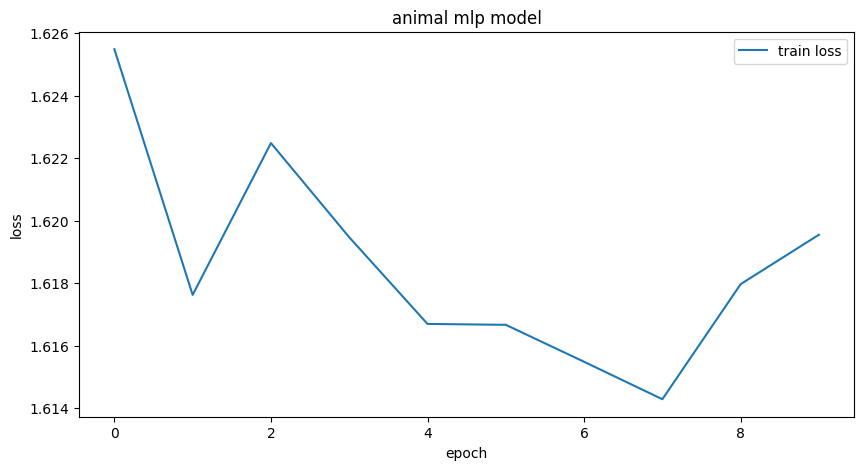

In [ ]:
# loss 그래프 그리기
plt.figure(figsize=(10,5)) # 그림판 크기 지정
plt.plot(h.history['loss'], label="train loss")
plt.legend() # 범례
plt.title("animal mlp model")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show() # 그림 보여주기

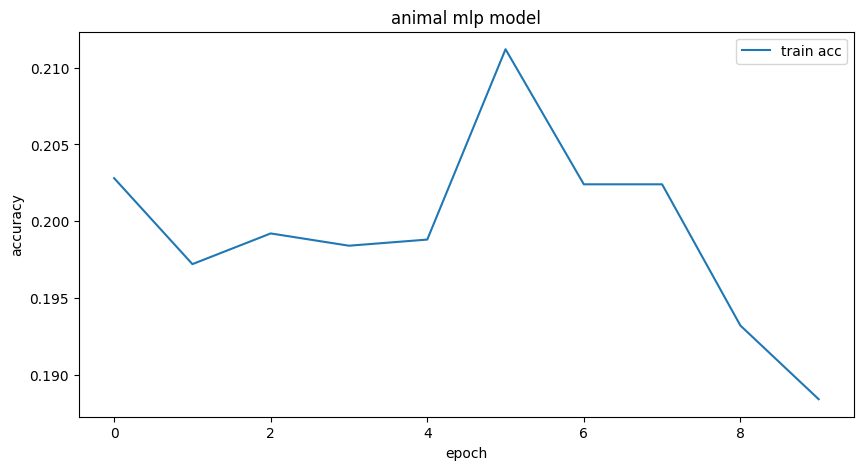

In [ ]:
# loss 그래프 그리기
plt.figure(figsize=(10,5)) # 그림판 크기 지정
plt.plot(h.history['accuracy'], label="train acc")
plt.legend() # 범례
plt.title("animal mlp model")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.show() # 그림 보여주기

### CNN활용 동물분류 모델 만들기
- Conv layer : 이미지의 특징을 강조하는 연산을 수행
- Pooling layer : 강조된 영역을 제외한 불필요한 부분을 제거하는 연산을 수행

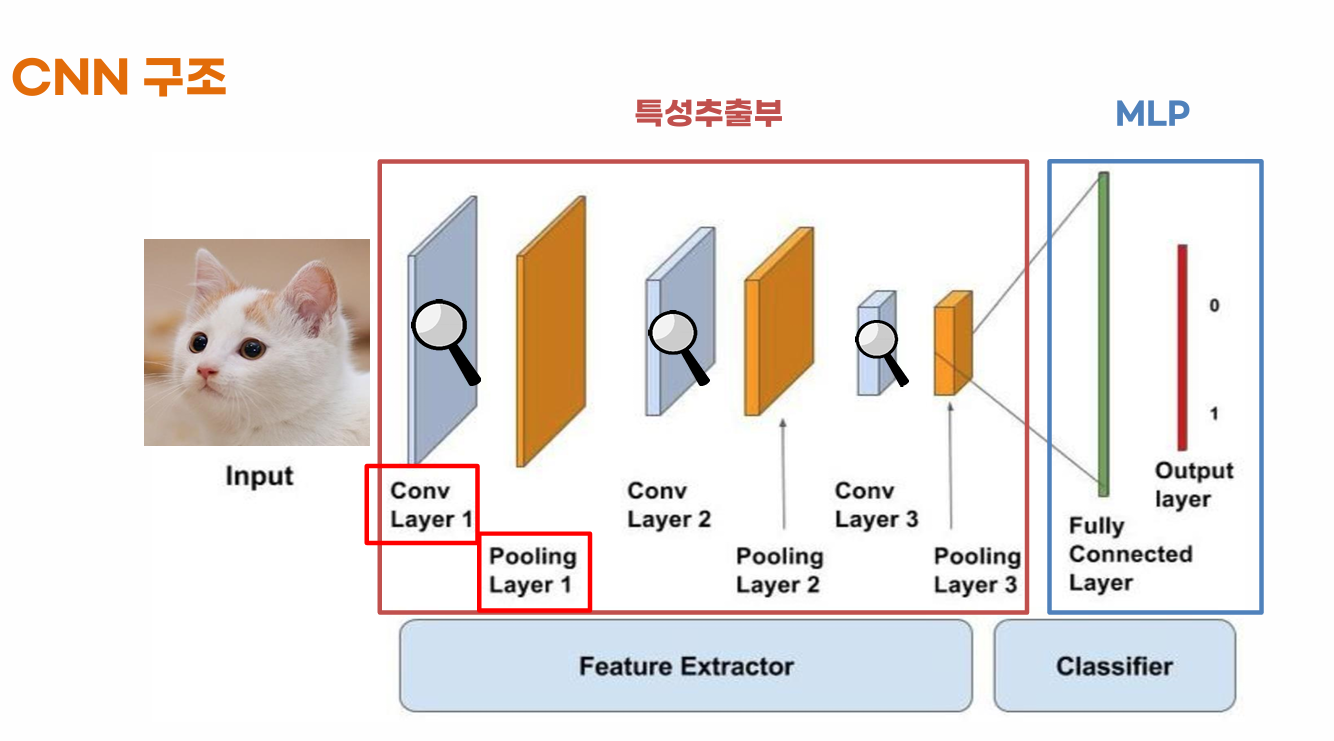

Convolutional Neural Network : 위치에 종속적인 학습을 벗어나기 위해 특징을 추출하는 단계를 앞쪽에 추가한 네트워크

In [ ]:
# 모델설계
cnn_model = Sequential() # 인공신경망 뼈대 생성
# 입력층
cnn_model.add(InputLayer(shape=(224, 224, 3))) # 사진데이터의 모양
## 특성 추출부
cnn_model.add(Conv2D(filters=64, # 돋보기역할의 이미지 커널 갯수
                     kernel_size = (3,3), # 돋보기의 크기 지정
                     activation="relu")) # 활성화 함수
cnn_model.add(Conv2D(filters=64, # 돋보기역할의 이미지 커널 갯수
                     kernel_size = (3,3), # 돋보기의 크기 지정
                     activation="relu")) # 활성화 함수
cnn_model.add(MaxPool2D()) # 불필요한 정보 제거

cnn_model.add(Conv2D(filters=128,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=128,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(MaxPool2D()) # 불필요한 정보 제거

cnn_model.add(Conv2D(filters=256,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=256,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=256,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(MaxPool2D()) # 불필요한 정보 제거

cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(MaxPool2D()) # 불필요한 정보 제거

cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(Conv2D(filters=512,
                     kernel_size = (3,3),
                     activation="relu"))
cnn_model.add(MaxPool2D()) # 불필요한 정보 제거

cnn_model.add(Flatten()) # 데이터를 1차원으로 평탄화
# 중간층
cnn_model.add(Dense(units=2048, activation='sigmoid'))
cnn_model.add(Dense(units=2048, activation='sigmoid'))
cnn_model.add(Dense(units=1024, activation='sigmoid'))
# 출력층
cnn_model.add(Dense(units=5, activation="softmax")) # 각 동물의 확률

In [ ]:
# 학습방법 및 평가방법 설정
cnn_model.compile(loss="sparse_categorical_crossentropy", # 손실함수
                  optimizer=Adam(learning_rate=0.0001), # 최적화알고리즘(경사하강법)
                  metrics=["accuracy"]) # 정확도

In [ ]:
# 학습
# fit을 호출하면 학습 log가 반환 된다.
h = cnn_model.fit(X_train_final,
                  y_train_final,
                  epochs = 30)

Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 47s 482ms/step - accuracy: 0.2580 - loss: 1.5841
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 379ms/step - accuracy: 0.3664 - loss: 1.3866
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 386ms/step - accuracy: 0.4288 - loss: 1.2919
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 390ms/step - accuracy: 0.4592 - loss: 1.2508
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 382ms/step - accuracy: 0.4880 - loss: 1.2114
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 384ms/step - accuracy: 0.5192 - loss: 1.1209
Epoch 7/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 386ms/step - accuracy: 0.5240 - loss: 1.1173
Epoch 8/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 382ms/step - accuracy: 0.5680 - loss: 1.0364
Epoch 9/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 384ms/step - accuracy: 0.5680 - loss: 1.0246
Epoch 10/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 385ms/step - accuracy: 0.6216 - loss: 0.9155
Epoch 11/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 383ms/step - accuracy: 0.6300 - loss: 0.8761
Epoch 12/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 30

#### 평가

In [ ]:
predict_result = cnn_model.predict(X_test_final)

16/16 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step


In [ ]:
# 모델의 예측값
y_pred = predict_result.argmax(1)

In [ ]:
print(classification_report(y_test_final, y_pred))

              precision    recall  f1-score   support

           0       0.43      0.58      0.49       100
           1       0.35      0.14      0.20       100
           2       0.53      0.58      0.56       100
           3       0.69      0.77      0.73       100
           4       0.55      0.57      0.56       100

    accuracy                           0.53       500
   macro avg       0.51      0.53      0.51       500
weighted avg       0.51      0.53      0.51       500



### Transfer learning (전이학습)
- 사전에 학습된 인공지능 모델을 활용해 적은 데이터를 가지고 좋은 성능의 모델을 만드는 방법
  1. 특성 추출부 활용하기
  2. 미세조정 방식 활용하기

In [ ]:
# 모델 다운로드
vgg16 = VGG16(
    include_top=False,
    weights='imagenet',
    input_shape=(224,224,3)
    )

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
vgg16.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model = Sequential() # 인공신경망 틀

# 사전학습 모델의 특성추출부 붙이기
cnn_model.add(vgg16)

cnn_model.add(Flatten()) # 데이터를 1차원으로 평탄화
# 중간층
cnn_model.add(Dense(units=2048, activation='sigmoid'))
cnn_model.add(Dense(units=2048, activation='sigmoid'))
cnn_model.add(Dense(units=1024, activation='sigmoid'))
# 출력층
cnn_model.add(Dense(units=5, activation="softmax")) # 각 동물의 확률

In [ ]:
# 학습방법 및 평가방법 설정
cnn_model.compile(loss="sparse_categorical_crossentropy", # 손실함수
                  optimizer=Adam(learning_rate=0.0001), # 최적화알고리즘(경사하강법)
                  metrics=["accuracy"]) # 정확도

In [ ]:
# 학습
# fit을 호출하면 학습 log가 반환 된다.
h = cnn_model.fit(X_train_final,
                  y_train_final,
                  epochs = 10)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 131s 765ms/step - accuracy: 0.7664 - loss: 0.6681
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 484ms/step - accuracy: 0.9360 - loss: 0.1901
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 484ms/step - accuracy: 0.9536 - loss: 0.1431
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 482ms/step - accuracy: 0.9788 - loss: 0.0624
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 485ms/step - accuracy: 0.9844 - loss: 0.0544
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 483ms/step - accuracy: 0.9696 - loss: 0.0880
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 482ms/step - accuracy: 0.9864 - loss: 0.0420
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 484ms/step - accuracy: 0.9956 - loss: 0.0138
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 484ms/step - accuracy: 1.0000 - loss: 0.0017
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 38s 487ms/step - accuracy: 0.9904 - loss: 0.0227


#### 평가

In [ ]:
predict_result = cnn_model.predict(X_test_final)

16/16 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step


In [ ]:
# 모델의 예측값
y_pred = predict_result.argmax(1)

In [ ]:
print(classification_report(y_test_final, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.57      0.73       100
           1       0.93      0.70      0.80       100
           2       1.00      0.65      0.79       100
           3       0.65      0.87      0.75       100
           4       0.56      0.96      0.71       100

    accuracy                           0.75       500
   macro avg       0.83      0.75      0.75       500
weighted avg       0.83      0.75      0.75       500

